[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jalonso1979/puremacro/blob/course-2026A-5.5.0/curso/notebooks/T05_C_staggered_did.ipynb)

> **Google Colab note**: the next cell installs `puremacro` and, if needed, fetches only the `curso/notebooks` folder (helpers, frozen data and models) from the public repository [jalonso1979/puremacro](https://github.com/jalonso1979/puremacro), edition `course-2026A-5.5.0`. It does not ask for Google Drive access.

In [1]:
# Environment setup: Google Colab, local Python or Juno (iPad)
import os
import sys
import subprocess
from pathlib import Path

_course_requirements = ['puremacro==5.5.0']
_course_edition = 'course-2026A-5.5.0'

def _safe_probe(p, is_dir=None):
    """Test paths without raising in the Juno sandbox."""
    try:
        p = Path(p)
        if is_dir is True:
            return p.is_dir()
        if is_dir is False:
            return p.is_file()
        return p.exists()
    except (OSError, PermissionError, TypeError, ValueError):
        return False

if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_course_requirements], check=True)
    # A separate directory per edition prevents reuse of helpers from another course.
    _repo = Path("/content/puremacro-" + _course_edition)
    if not _safe_probe(_repo, is_dir=True):
        subprocess.run(["git", "clone", "-q", "--depth", "1", "--filter=blob:none", "--sparse",
                        "--branch", _course_edition, "https://github.com/jalonso1979/puremacro.git", str(_repo)], check=True)
    subprocess.run(["git", "-C", str(_repo), "checkout", "--detach", _course_edition], check=True)
    subprocess.run(["git", "-C", str(_repo), "sparse-checkout", "set", "curso/notebooks"], check=True)
    _course_status = subprocess.run(["git", "-C", str(_repo), "status", "--porcelain",
                                     "--untracked-files=normal", "--", "curso/notebooks"],
                                    check=True, capture_output=True, text=True).stdout
    if _course_status.strip():
        raise RuntimeError("The cached course edition was modified; use a fresh Colab runtime for the frozen edition.")
    os.chdir(_repo / "curso/notebooks")

# Locate the course helpers for local Python, Colab and Juno.
_candidates = [Path.cwd(), Path.cwd() / "notebooks", Path.cwd() / "curso/notebooks"]
try:
    _candidates.insert(0, Path(__file__).resolve().parent)
except (NameError, OSError):
    pass
for _c in _candidates:
    if _safe_probe(_c / "_nbstyle.py", is_dir=False):
        if str(_c) not in sys.path:
            sys.path.insert(0, str(_c))
        break

import puremacro
if puremacro.__version__ != "5.5.0":
    raise RuntimeError("This course edition requires puremacro==5.5.0; install it and restart the kernel.")

# Cached reference responses are the reproducible default; live models are optional.
os.environ.setdefault("MAV_LLM_MODE", "cache")

%matplotlib inline
try:
    import _nbstyle
    _nbstyle.apply_style()
except ImportError:
    pass

Matplotlib is building the font cache; this may take a moment.


# Staggered Difference-in-Differences and the Breakdown of Two-Way Fixed Effects

When evaluating macroeconomic interventions—from state minimum wage changes and unemployment insurance duration rules to regional tax incentives and public infrastructure programs—empirical researchers routinely confront policies adopted at different dates across jurisdictions. For decades, the default empirical specification was the linear **Two-Way Fixed Effects (TWFE)** regression:
$$ Y_{it} = \alpha_i + \lambda_t + \beta^{TWFE} D_{it} + \varepsilon_{it} $$
where $\alpha_i$ captures time-invariant unit characteristics, $\lambda_t$ absorbs aggregate time shocks, and $D_{it} = \mathbb{1}\{t \ge G_i\}$ indicates treatment status.

Recent econometric breakthroughs (Goodman-Bacon 2021; de Chaisemartin & D'Haultfoeuille 2020; Sun & Abraham 2021; Callaway & Sant'Anna 2021) demonstrated that this classical approach breaks down under heterogeneous or dynamic treatment effects. Ordinary Least Squares silently constructs **forbidden comparisons**, using early-treated units—which are already experiencing evolving post-treatment dynamics—as the "control group" for later-adopting cohorts. Differencing against an already-treated unit subtracts off its ongoing treatment trajectory, assigning **negative weights** to treated observations. Under dynamic phase-in, $\hat{\beta}^{TWFE}$ can flip sign entirely, reporting a negative policy coefficient when the true treatment effect is strictly positive everywhere.

This notebook examines the mathematical foundations of this failure, decomposes the negative weighting bias using the Frisch-Waugh-Lovell theorem, and implements modern heterogeneity-robust estimators: **Callaway & Sant'Anna (2021)** group-time average treatment effects and **Sun & Abraham (2021)** interaction-weighted event studies.

## Econometric Foundations: Decomposing the TWFE Failure

### Potential Outcomes and Timing Cohorts
Consider a panel of units $i = 1, \dots, N$ observed over time periods $t = 1, \dots, T$. Unit $i$ adopts policy treatment at calendar date $G_i \in \{g_1, g_2, \dots, g_K\} \cup \{\infty\}$, where $G_i = \infty$ denotes never-treated units. For each period $t$, let $Y_{it}(0)$ be the potential outcome without treatment, and $Y_{it}(g)$ the potential outcome if adopted at time $g$. The observed outcome is:
$$ Y_{it} = Y_{it}(0) + \sum_{g} \mathbb{1}\{G_i = g, t \ge g\}\,\tau_{it}(g, t) $$
where $\tau_{it}(g, t) = Y_{it}(g) - Y_{it}(0)$ is the unit-specific causal effect at elapsed exposure $e = t - g$.

### The Goodman-Bacon (2021) 2x2 Decomposition
Goodman-Bacon proved that the linear regression coefficient $\hat{\beta}^{TWFE}$ is an exact variance-weighted average of all possible $2 \times 2$ difference-in-differences estimators across timing cohorts:
$$ \beta^{TWFE} = \sum_{k \neq U} s_{kU} \beta_{kU}^{2 \times 2} + \sum_{k} \sum_{j > k} \left[ s_{kj}^k \beta_{kj}^{2 \times 2, k} + s_{jk}^j \beta_{jk}^{2 \times 2, j} \right] $$
where weights $s$ are positive and sum to 1. The three types of $2 \times 2$ comparisons are:
1. **Treated vs. Untreated ($\beta_{kU}^{2 \times 2}$)**: Cohort $k$ compared against never-treated units $U$ (clean counterfactual).
2. **Earlier vs. Later before adoption ($\beta_{kj}^{2 \times 2, k}$)**: Early cohort $k$ compared against later cohort $j$ over periods where $j$ is not yet treated (clean counterfactual).
3. **Later vs. Earlier after adoption ($\beta_{jk}^{2 \times 2, j}$)**: Later cohort $j$ compared against already-treated cohort $k$ (**the forbidden comparison**).

In this third component, cohort $k$ is already treated. If the policy effect grows over time ($\tau(e)$ rises with exposure $e$), cohort $k$'s outcome rises between periods. Using cohort $k$ as a control subtracts its post-treatment trajectory from cohort $j$'s response:
$$ \mathbb{E}[\hat{\beta}_{jk}^{2 \times 2, j}] = \text{ATT}_{j, post} - \Delta \text{ATT}_{k, post} $$
If treatment effects grow rapidly ($\Delta \text{ATT}_{k, post} > \text{ATT}_{j, post}$), this comparison yields a negative estimate despite positive causal effects!

### Negative Weights via Frisch-Waugh-Lovell
By the Frisch-Waugh-Lovell theorem, de Chaisemartin & D'Haultfoeuille (2020) express $\hat{\beta}^{TWFE}$ as a linear combination of all treated cell-level treatment effects:
$$ \hat{\beta}^{TWFE} = \sum_{(i,t): D_{it}=1} w_{it} \tau_{it}, \qquad w_{it} = \frac{\tilde{D}_{it}}{\sum_{j,s} \tilde{D}_{js}^2} $$
where $\tilde{D}_{it} = D_{it} - \bar{D}_i - \bar{D}_t + \bar{D}$ is the residual from projecting $D_{it}$ onto unit and time fixed effects. For early-treated units in late periods, both unit mean $\bar{D}_i$ and time mean $\bar{D}_t$ are large, forcing $\tilde{D}_{it} < 0$. These negative weights explain how positive treatment effects produce negative regression coefficients.

### The Callaway & Sant'Anna (2021) and Sun & Abraham (2021) Solutions
Modern estimators eliminate forbidden comparisons by restricting the control group to clean counterfactuals (never-treated or not-yet-treated units).
**Callaway & Sant'Anna (2021)** define the **group-time average treatment effect** for cohort $g$ at time $t$, differenced against base period $g-1$ and a clean control group $C$:
$$ \text{ATT}(g, t) = \mathbb{E}\left[ Y_t - Y_{g-1} \mid G = g \right] - \mathbb{E}\left[ Y_t - Y_{g-1} \mid C \right] $$
Aggregating $\text{ATT}(g, t)$ across cohorts by event time $e = t - g$ yields the event-study profile. Callaway & Sant'Anna weight each cohort by its size (their eq. 3.4; equation numbers from arXiv:1803.09015v4):
$$ \theta_{es}(e) = \sum_{g} \mathbb{1}\{g + e \le T\}\, P(G = g \mid G + e \le T)\, \text{ATT}(g, g+e), $$
estimated with the shares $n_g / \sum_{g'} n_{g'}$ of the cohorts observed $e$ periods after adoption.
**Sun & Abraham (2021)** estimate cohort-specific effects $\text{CATT}(g, e)$, the same building block as $\text{ATT}(g, g+e)$, and aggregate them with the same cohort shares (the interaction-weighted, IW, estimator):
$$ \text{ATT}_{\text{SA}}(e) = \sum_{g} w_g \,\text{CATT}(g, e), \qquad w_g = \frac{n_g}{\sum_{g'} n_{g'}}. $$
Without covariates and with never-treated controls, Sun & Abraham note that their procedure coincides with Callaway & Sant'Anna's (discussion after their Proposition 5): two routes to one estimand, not two weighting rules.

In [2]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_cwd = Path.cwd()
sys.path.insert(0, str(_cwd if (_cwd / "_nbstyle.py").exists() else _cwd / "notebooks"))
import _nbstyle
_nbstyle.apply_style()

from puremacro.did import callaway_santanna, sun_abraham

## 1. Canonical Staggered Adoption Panel with a Known Benchmark

To establish an econometric benchmark, we simulate a staggered adoption panel where parallel trends hold by construction. Three cohorts adopt policy treatment at $t = 5, 8, 11$, while a fourth cohort remains never-treated ($G = \infty$).

In this initial baseline, we plant a constant, homogeneous treatment kick $\tau = +1.0$. Because effects are homogeneous, the true dynamic event-study profile is flat at $+1.0$ for all post-treatment horizons $e \ge 0$.

In [3]:
rng = np.random.default_rng(20240529)

N_UNITS, T = 90, 14
COHORTS = (5, 8, 11, np.nan)          # three treated cohorts + never-treated
TRUE_ATT, SIGMA = 1.0, 0.3

assign = rng.choice(len(COHORTS), size=N_UNITS, replace=True)
unit_fe = rng.standard_normal(N_UNITS)
time_fe = rng.standard_normal(T) * 0.3

rows = []
for i in range(N_UNITS):
    g = COHORTS[assign[i]]
    for t in range(1, T + 1):
        treated = 1.0 if (not pd.isna(g)) and t >= g else 0.0
        y = unit_fe[i] + time_fe[t - 1] + TRUE_ATT * treated + SIGMA * rng.standard_normal()
        rows.append({"unit": i, "time": t, "y": y, "treat_time": g})
panel = pd.DataFrame(rows)

n_never = int(panel.groupby("unit")["treat_time"].first().isna().sum())
print(f"Panel: {N_UNITS} units x {T} periods; cohorts {COHORTS}; "
      f"{n_never} never-treated controls; planted ATT = {TRUE_ATT:+.1f}")

Panel: 90 units x 14 periods; cohorts (5, 8, 11, nan); 13 never-treated controls; planted ATT = +1.0


### Identification Intuition: The Role of the Clean Control Group

This baseline represents the optimal laboratory environment for causal inference:
1. **Parallel counterfactual trends**: Prior to adoption, differences across units are governed solely by the time-invariant unit fixed effects $\alpha_i$.
2. **Clean control availability**: The never-treated cohort ($G=\infty$) provides an uncontaminated counterfactual group throughout the entire panel.
3. **Homogeneous response**: The treatment kick is uniform across all adopting units.

Under these idealized conditions, both classical TWFE and modern estimators recover the true effect. The divergence between them emerges as soon as treatment dynamics or cohort heterogeneity are introduced.

## 2. Heterogeneity-Robust Estimation: Callaway-Sant'Anna & Sun-Abraham

We build the estimator from scratch and then check it against `puremacro`. For each cohort $g$ and period $t$, $\text{ATT}(g,t)$ is a $2 \times 2$ difference in differences: the change in the mean outcome of cohort $g$ from the base period $g-1$ to $t$, minus the same change among the never-treated units. Every aggregate then weights the cohorts by their size $n_g$ (Callaway & Sant'Anna 2021, Section 3):
- **Event study** (eq. 3.4): $\hat{\theta}_{es}(e) = \sum_{g \in \mathcal{G}_e} \frac{n_g}{\sum_{g' \in \mathcal{G}_e} n_{g'}}\, \widehat{\text{ATT}}(g, g+e)$, where $\mathcal{G}_e$ is the set of cohorts observed $e$ periods after adoption.
- **Overall effect** (eq. 3.11, the summary the paper recommends): $\hat{\theta}^O_{sel} = \sum_{g} \frac{n_g}{\sum_{g'} n_{g'}}\, \hat{\theta}_{sel}(g)$, where $\hat{\theta}_{sel}(g)$ (eq. 3.7) averages cohort $g$'s post-treatment cells. It is the average effect among all units that ever participate, the analogue of the $2 \times 2$ ATT.
- **Cell-weighted overall effect** (eq. 3.10): $\hat{\theta}^O_W$ weights every post-treatment cell by its cohort's size, so cohorts treated for longer, which have more post-treatment cells, count more.

Sun-Abraham's IW event study uses the same cohort shares, so on this design it must reproduce $\hat{\theta}_{es}(e)$ exactly; its default overall summary is $\hat{\theta}^O_W$. The plain mean of the post-treatment cells, which `callaway_santanna(..., aggregation="unweighted")` reports, is not one of the paper's estimands; we print it only for comparison. By default (`aggregation="group"`) `callaway_santanna` reports $\hat{\theta}^O_{sel}$ as `att_overall`, and the cell below checks the hand-built aggregates against it. Inference resamples whole units and recomputes every aggregate, cohort sizes included, in each bootstrap draw.

In [4]:
def to_wide(df):
    """Outcome as a units x periods array, each unit's cohort (inf = never treated), periods."""
    Y = df.pivot(index="unit", columns="time", values="y").sort_index(axis=1)
    G = df.groupby("unit")["treat_time"].first().reindex(Y.index).fillna(np.inf)
    return Y.to_numpy(), G.to_numpy(), Y.columns.to_numpy()

def cs_by_hand(Y, G, periods):
    """Callaway-Sant'Anna from scratch: ATT(g,t) cells and their cohort-size-weighted aggregates."""
    never = np.isinf(G)
    cohorts = np.unique(G[~never])
    n_g = np.array([np.sum(G == g) for g in cohorts], dtype=float)    # cohort sizes
    att = np.empty((len(cohorts), len(periods)))
    for k, g in enumerate(cohorts):
        dY = Y - Y[:, periods == g - 1]                  # long difference from the base period g-1
        att[k] = dY[G == g].mean(axis=0) - dY[never].mean(axis=0)
    e = (periods[None, :] - cohorts[:, None]).astype(int)   # event time of every (g, t) cell
    w = np.broadcast_to(n_g[:, None], att.shape)             # each cell carries its cohort's size
    event_time = np.unique(e)
    post = e >= 0
    theta_g = np.array([att[k, post[k]].mean() for k in range(len(cohorts))])       # eq. 3.7
    return {"cohorts": cohorts, "n_g": n_g, "att": att, "e": e, "event_time": event_time,
            "es": np.array([np.sum(w[e == v] * att[e == v]) / np.sum(w[e == v])
                            for v in event_time]),                                  # eq. 3.4
            "theta_g": theta_g,
            "sel": float(n_g @ theta_g / n_g.sum()),                                # eq. 3.11
            "simple": float(np.sum(w[post] * att[post]) / np.sum(w[post])),         # eq. 3.10
            "equal": float(att[post].mean())}    # plain mean of the post cells: not a CS estimand

def cs_bootstrap(df, n_boot=400, seed=0, alpha=0.10):
    """Resample whole units; recompute every aggregate, cohort sizes included, in each draw."""
    Y, G, periods = to_wide(df)
    fit = cs_by_hand(Y, G, periods)
    rng_b = np.random.default_rng(seed)
    es_draws, sel_draws = np.empty((n_boot, len(fit["es"]))), np.empty(n_boot)
    for b in range(n_boot):
        idx = rng_b.integers(0, len(G), size=len(G))
        draw = cs_by_hand(Y[idx], G[idx], periods)
        assert np.array_equal(draw["cohorts"], fit["cohorts"])   # every cohort is drawn
        es_draws[b], sel_draws[b] = draw["es"], draw["sel"]
    q = [alpha / 2, 1 - alpha / 2]
    lo, hi = np.quantile(es_draws, q, axis=0)
    fit["es_table"] = pd.DataFrame({"event_time": fit["event_time"], "att": fit["es"],
                                    "se": es_draws.std(axis=0, ddof=1), "lo": lo, "hi": hi})
    fit["sel_se"] = float(sel_draws.std(ddof=1))
    fit["sel_lo"], fit["sel_hi"] = (float(v) for v in np.quantile(sel_draws, q))
    return fit

cs = cs_bootstrap(panel)
periods = np.sort(panel["time"].unique())
cells = pd.DataFrame({"g": np.repeat(cs["cohorts"], len(periods)),
                      "t": np.tile(periods, len(cs["cohorts"])),
                      "event_time": cs["e"].ravel(), "att_hand": cs["att"].ravel()})

# Internal check 1: the hand-built ATT(g,t) cells equal puremacro's.
lib = callaway_santanna(panel, n_boot=0)
cells = cells.merge(lib.att_gt[["g", "t", "att"]], on=["g", "t"])
gap_gt = float((cells["att_hand"] - cells["att"]).abs().max())
# Internal check 2: Sun-Abraham's interaction-weighted event study is eq. 3.4.
sa = sun_abraham(panel, n_boot=0)
es_sa = sa.att_event_study.sort_values("event_time")
gap_sa = float(np.abs(es_sa["att"].to_numpy() - cs["es"]).max())
assert gap_gt < 1e-10 and gap_sa < 1e-10, (gap_gt, gap_sa)
assert abs(sa.att_overall - cs["simple"]) < 1e-10    # SA's default overall summary is eq. 3.10

# Internal check 3: the library's overall summaries are the hand-built ones.
lib_unw = callaway_santanna(panel, n_boot=0, aggregation="unweighted")
assert abs(lib.att_overall - cs["sel"]) < 1e-10        # default aggregation="group" is eq. 3.11
assert abs(lib_unw.att_overall - cs["equal"]) < 1e-10  # "unweighted" is the plain mean

sizes = ", ".join(f"g={int(g)}: {int(n)}" for g, n in zip(cs["cohorts"], cs["n_g"]))
print(f"ATT(g,t): {len(cells)} cells; max |by hand - callaway_santanna| = {gap_gt:.1e}")
print(f"cohort sizes n_g: {sizes}; never treated: {n_never}")
print(f"event study eq. 3.4 vs sun_abraham (IW): max |diff| = {gap_sa:.1e}")
print(f"theta^O_sel (eq. 3.11) = {cs['sel']:+.4f} | theta^O_W (eq. 3.10) = {cs['simple']:+.4f}"
      f" | plain mean of post cells = {cs['equal']:+.4f}")
print(f"callaway_santanna(...).att_overall = {lib.att_overall:+.4f} (theta^O_sel by hand {cs['sel']:+.4f})"
      f" | aggregation='unweighted': {lib_unw.att_overall:+.4f} (plain mean by hand {cs['equal']:+.4f})")

ATT(g,t): 42 cells; max |by hand - callaway_santanna| = 4.4e-16
cohort sizes n_g: g=5: 25, g=8: 27, g=11: 25; never treated: 13
event study eq. 3.4 vs sun_abraham (IW): max |diff| = 2.2e-16
theta^O_sel (eq. 3.11) = +1.1379 | theta^O_W (eq. 3.10) = +1.1292 | plain mean of post cells = +1.1292
callaway_santanna(...).att_overall = +1.1379 (theta^O_sel by hand +1.1379) | aggregation='unweighted': +1.1292 (plain mean by hand +1.1292)


## 3. Econometric Validation and Statistical Diagnostics

To verify the integrity of the estimators, we execute four formal hypothesis checks:
1. **Overall ATT**: $\hat{\theta}^O_{sel}$ and $\hat{\theta}^O_W$ lie near the planted effect ($\tau = 1.0$). We also report whether the 90% interval of $\hat{\theta}^O_{sel}$ contains the truth; that interval comes from bootstrapping the aggregate itself, not from averaging the endpoints of the pointwise event-study bands.
2. **Base-Period Normalization ($e = -1$)**: The coefficient at event time $e = -1$ must be exactly zero, as all differences are taken with respect to $g-1$.
3. **Placebo Pre-Trends ($e \le -2$)**: Prior to adoption, differences between cohorts and clean controls must be statistically indistinguishable from zero ($|t| < 2.5$, with bootstrap standard errors).
4. **Post-Treatment Profile Tracking**: Estimated post-treatment effects $\text{ATT}(e)$ must hover near the true $+1.0$ level across all horizons $e \ge 0$.

In [5]:
es_cs = cs["es_table"]
post = es_cs[es_cs["event_time"] >= 0]

assert abs(cs["sel"] - TRUE_ATT) < 0.25, cs["sel"]
assert abs(cs["simple"] - TRUE_ATT) < 0.25, cs["simple"]

# Base period (event_time == -1) is the normalization point: exactly 0 by construction
base = es_cs[es_cs["event_time"] == -1]
assert len(base) == 1 and abs(float(base["att"].iloc[0])) < 1e-12

# The earlier leads (event_time <= -2) are genuine placebos: the DGP has parallel
# trends, so they must be statistically indistinguishable from zero.
leads = es_cs[es_cs["event_time"] <= -2]
lead_t = leads["att"].abs() / leads["se"]
assert (lead_t < 2.5).all(), leads.to_dict("records")

# Every post-treatment horizon tracks the constant true effect.
for _, r in post.iterrows():
    assert abs(r["att"] - TRUE_ATT) < 0.40, (r["event_time"], r["att"])

# The interval is for the aggregate itself: its own bootstrap draws, not averaged endpoints.
covers = cs["sel_lo"] <= TRUE_ATT <= cs["sel_hi"]
print(f"CS overall theta^O_sel = {cs['sel']:+.3f}   (se {cs['sel_se']:.3f}; "
      f"90% unit-bootstrap CI [{cs['sel_lo']:+.3f}, {cs['sel_hi']:+.3f}])")
print(f"SA overall theta^O_W   = {sa.att_overall:+.3f}   true = {TRUE_ATT:+.3f}")
print(f"Does the interval contain the planted truth? {covers}  "
      f"((theta^O_sel - truth) / se = {(cs['sel'] - TRUE_ATT) / cs['sel_se']:.2f})")
print(f"Largest |t| among the leads e <= -2: {lead_t.max():.2f}")

CS overall theta^O_sel = +1.138   (se 0.077; 90% unit-bootstrap CI [+1.005, +1.258])
SA overall theta^O_W   = +1.129   true = +1.000
Does the interval contain the planted truth? False  ((theta^O_sel - truth) / se = 1.78)
Largest |t| among the leads e <= -2: 1.66


### Econometric Interpretation: Placebo Leads vs. Base Normalization

The recommended summary is $\hat{\theta}^O_{sel} = +1.138$ and the cell-weighted one $\hat{\theta}^O_W = +1.129$, both near the planted $+1.00$. The 90% unit-bootstrap interval for $\hat{\theta}^O_{sel}$, $[+1.005, +1.258]$, **misses** the truth: this sample drew an estimate 1.78 standard errors above it. A 90% interval misses in one sample out of ten; we report the miss rather than change the seed. An earlier version of this lesson averaged the endpoints of the pointwise event-study bands into an "overall interval". That is not an interval for any aggregate: it ignores the correlation between event times and uses weights unrelated to the estimator.

Econometricians must distinguish between two types of pre-treatment points:
- **Mechanical Normalization ($e = -1$)**: The coefficient at event time $e = -1$ is identically zero by construction. Because every group-time contrast $\text{ATT}(g, t)$ is differenced against base period $g-1$, this point does *not* validate parallel trends; it is merely an anchor.
- **Genuine Placebo Leads ($e \le -2$)**: Points at $e = -2, -3, \dots$ compare the cohort and control across pre-treatment periods where neither unit is treated. They test parallel counterfactual trajectories. Here the largest lead $|t|$ is 1.66, so no lead is individually significant. These are pointwise tests, not a joint test, and failing to reject does not prove parallel trends.

### Event-Study Dynamics under Heterogeneity-Robust Estimation

The event-study plot traces causal propagation over relative time. Pre-treatment placebo leads oscillate around zero; at the adoption boundary ($e = 0$), the estimated trajectory jumps directly to the true $+1.0$ line and remains stable. The shaded region is the 90% pointwise percentile band from 400 unit-bootstrap draws of $\hat{\theta}_{es}(e)$ itself; it does not cover the whole curve simultaneously.

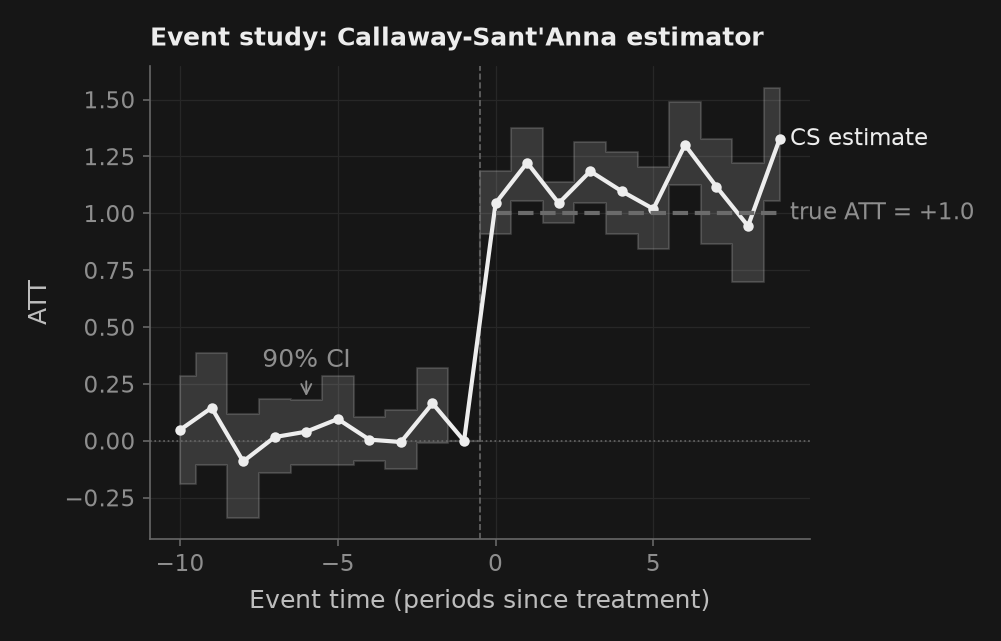

In [6]:
cols = _nbstyle.palette(2)
fig, ax = _nbstyle.figura()
ax.axhline(0.0, color=_nbstyle.SPINE, linewidth=0.8, linestyle=":")
ax.axvline(-0.5, color=_nbstyle.SPINE, linewidth=0.8, linestyle="--")
ax.fill_between(es_cs["event_time"], es_cs["lo"], es_cs["hi"], color=_nbstyle.BANDA,
                step="mid")
ax.plot(es_cs["event_time"], es_cs["att"], color=cols[0], ls="-", marker="o", markersize=4,
        label="CS estimate")
post_e = es_cs[es_cs["event_time"] >= 0]
ax.plot(post_e["event_time"], [TRUE_ATT] * len(post_e), color=cols[1],
        linestyle="--", label=f"true ATT = {TRUE_ATT:+.1f}")
# the band is named over a placebo lead, where nothing else sits above it
r = es_cs[es_cs["event_time"] == -6].iloc[0]
ax.annotate("90% CI", xy=(r["event_time"], r["hi"]), xytext=(0, 16),
            textcoords="offset points", ha="center", color=_nbstyle.NOTA,
            arrowprops=_nbstyle.FLECHA)
ax.set_xlabel("Event time (periods since treatment)")
ax.set_ylabel("ATT")
ax.set_title("Event study: Callaway-Sant'Anna estimator")
ax.locator_params(axis="x", integer=True)   # event time counts whole periods
_nbstyle.etiquetar(ax, donde="fin")
plt.show()


### Two Routes, One Estimand: Callaway-Sant'Anna and Sun-Abraham

Callaway-Sant'Anna's eq. 3.4 and Sun-Abraham's IW estimator aggregate the same $\text{ATT}(g, t)$ matrix with the same cohort shares $n_g / \sum n_{g'}$, so the two event-study paths below coincide up to floating-point rounding (see the gap printed by the check above). What differs is the overall summary each routine reports by default: $\hat{\theta}^O_{sel}$ averages the three cohort means, while Sun-Abraham's $\hat{\theta}^O_W$ averages the post-treatment cells, which gives cohort $g = 5$, treated for the most periods, the largest weight. With a common effect every rule targets $+1.0$; the exercise at the end builds a panel where the rules come apart.

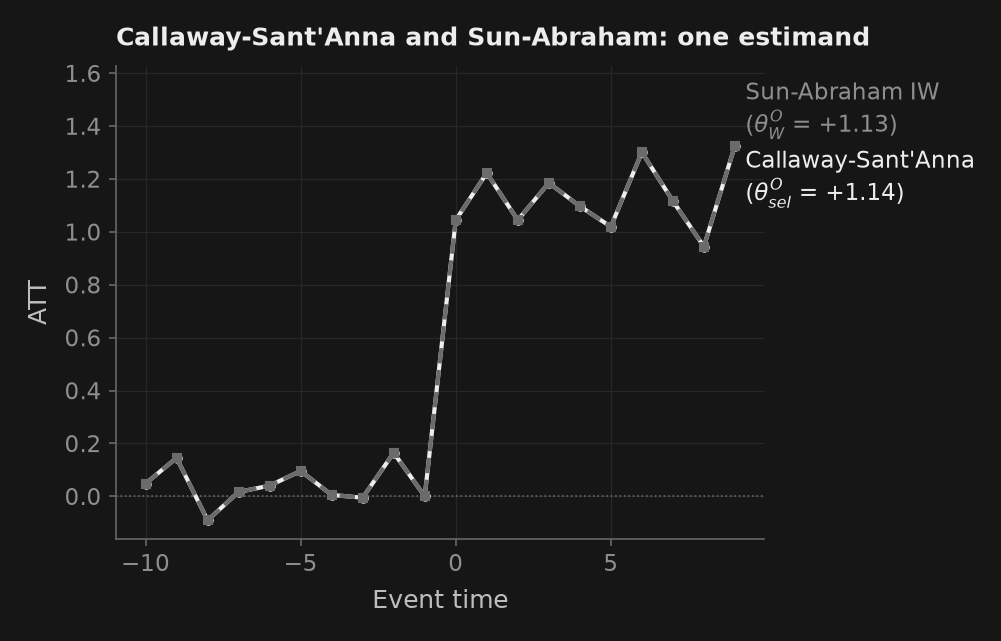

In [7]:
fig, ax = _nbstyle.figura()
ax.axhline(0.0, color=_nbstyle.SPINE, linewidth=0.8, linestyle=":")
ax.plot(es_cs["event_time"], es_cs["att"], color=cols[0], ls="-", marker="o", markersize=4,
        label=f"Callaway-Sant'Anna\n($\\theta^O_{{sel}}$ = {cs['sel']:+.2f})")
ax.plot(es_sa["event_time"], es_sa["att"], color=cols[1], marker="s",
        markersize=4, linestyle="--",
        label=f"Sun-Abraham IW\n($\\theta^O_W$ = {sa.att_overall:+.2f})")
ax.set_xlabel("Event time")
ax.set_ylabel("ATT")
ax.set_ylim(top=es_cs["att"].max() + 0.30)   # room for the stacked names under the title
ax.set_title("Callaway-Sant'Anna and Sun-Abraham: one estimand")
ax.locator_params(axis="x", integer=True)   # event time counts whole periods
_nbstyle.etiquetar(ax, donde="fin", sep=3.0)   # the two paths coincide: stacked two-line names
plt.show()


### Dissecting the Building Blocks: Cohort-Specific Group-Time Trajectories

The panel below plots the primitive group-time treatment effects $\text{ATT}(g, t)$ separately for each adoption cohort ($g=5, 8, 11$). Each curve remains flat at zero prior to treatment ($e < 0$) and transitions to orbit the true $+1.0$ level upon adoption. The event-study estimates displayed above are averages across these cohort paths, weighted by cohort size.

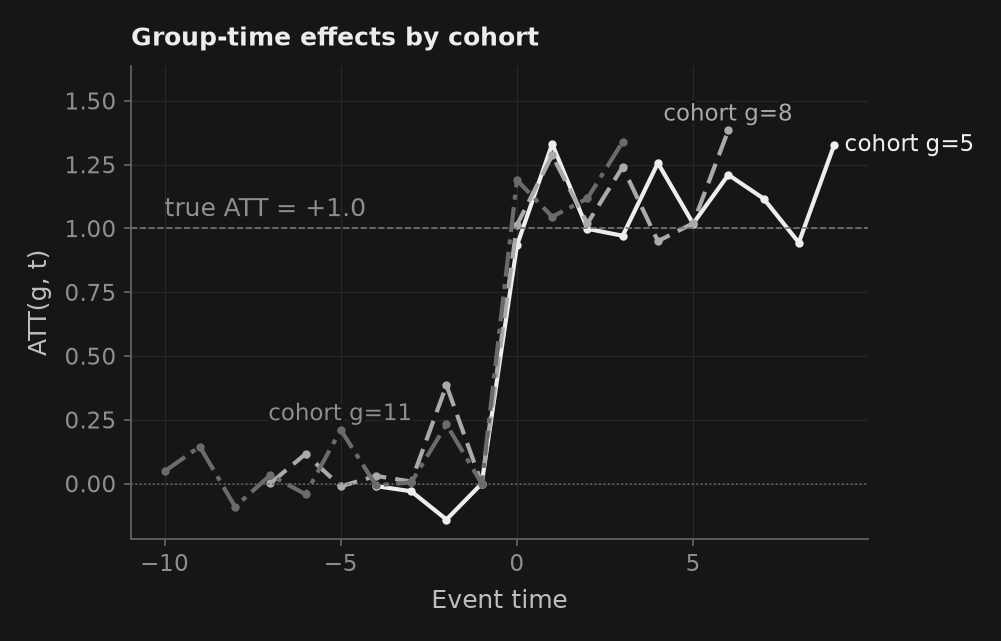

In [8]:
fig, ax = _nbstyle.figura()
gt = cells
cohorts = sorted(gt["g"].unique())
ccols = _nbstyle.palette(len(cohorts))
lineas = {}
for c, color in zip(cohorts, ccols):
    sub = gt[gt["g"] == c].sort_values("event_time")
    lineas[int(c)] = ax.plot(sub["event_time"], sub["att"], marker="o", markersize=3,
                             color=color, label=f"cohort g={int(c)}")[0]
ax.axhline(0.0, color=_nbstyle.SPINE, linewidth=0.8, linestyle=":")
ax.axhline(TRUE_ATT, color=_nbstyle.gris("0.4"), linewidth=0.8, linestyle="--")
ax.annotate(f"true ATT = {TRUE_ATT:+.1f}", xy=(gt["event_time"].min(), TRUE_ATT),
            xytext=(0, 3), textcoords="offset points", ha="left", va="bottom",
            color=_nbstyle.NOTA)
ax.set_ylim(top=gt["att"].max() + 0.25)      # room for a name above the highest point
ax.set_xlabel("Event time")
ax.set_ylabel("ATT(g, t)")
ax.set_title("Group-time effects by cohort")
ax.locator_params(axis="x", integer=True)   # event time counts whole periods
# each cohort is named where its path stands clear of the other two: g=5 after its
# last point, g=8 above its last point, g=11 above its pre-treatment peak
_nbstyle.etiquetar(ax, artistas=[lineas[5]], donde="fin")
_nbstyle.etiquetar(ax, artistas=[lineas[8]], donde=6.0)
_nbstyle.etiquetar(ax, artistas=[lineas[11]], donde=-5.0)
plt.show()


### Econometric Insight: Cohort Alignment and the Masking of TWFE Failure

In this baseline exercise, all three cohorts experience the identical flat effect $\tau = +1.0$. Consequently, their $\text{ATT}(g, t)$ trajectories fluctuate around the same $+1.0$ level, apart from sampling noise. Because there is no dynamic growth across elapsed time ($\Delta \text{ATT} = 0$), the forbidden comparison term in the Goodman-Bacon decomposition drops out:
$$ \mathbb{E}[\hat{\beta}_{jk}^{2 \times 2, j}] = \text{ATT}_{j, post} - 0 = \text{ATT}_{j, post} $$
This constant-effect specification completely masks the vulnerability of two-way fixed effects! In applied macroeconomics, treatment effects are rarely instantaneous and static; policies phase in, agents adapt, and capital accumulates. The next section unleashes dynamic treatment effects to demonstrate how TWFE breaks down and how Callaway-Sant'Anna resolves the crisis.

## 4. Interactive Empirical Experiment: TWFE Negative Weighting Diagnostic & Staggered DiD Resolution

### The Economic Dilemma: Dynamic Phase-in of State Macroeconomic Policies
Consider a state-level policy adoption—such as a phased increase in statutory minimum wages, a staged corporate tax credit, or job training subsidies—evaluated across US regional panels (`data_curso/paro_estatal_mensual.csv`). 
When a policy phases in, its causal impact compounds over time: $\tau_i(e) = 1.0 + 1.2e$, where $e = t - g$ is elapsed exposure. In early adoption waves, the effect starts at $+1.0$ and climbs to $>+15.0$ in later periods.

### The Experiment: Demonstrating the Catastrophic Sign Flip
1. **Data Generating Process**: We construct a panel of $N = 100$ units observed across $T = 16$ periods with two adoption cohorts:
   - Cohort 1 ($g_1 = 2$, 50 units): Early adopters.
   - Cohort 2 ($g_2 = 12$, 50 units): Late adopters.
   - Dynamic causal response: $\tau(e) = 1.0 + 1.2e$ for all treated units ($D_{it} = 1$).
2. **Empirical Diagnostic**:
   - Compute the true average effect over the treated cells of this noiseless panel ($t = 0, \dots, 15$): $\frac{1}{\sum D_{it}} \sum_{D_{it}=1} \tau_{it} = +7.467$. Every single treated cell has a strictly positive effect!
   - Extract the Frisch-Waugh-Lovell regression weights $w_{it} = \tilde{D}_{it} / \sum \tilde{D}_{js}^2$ underlying the naive TWFE regression.
   - Document the sign reversal: naive TWFE yields $\hat{\beta}^{TWFE} = -1.600$ due to 22.2% of treated cells carrying negative weights (total negative weight mass $-0.6667$).
3. **Heterogeneity-Robust Resolution**:
   - The noiseless panel has no never-treated units, so we simulate a second panel ($t = 1, \dots, 16$) that adds 20 never-treated units and noise, and estimate Callaway & Sant'Anna (2021) with the functions of Section 2.
   - Compare each summary with its own planted value on that second panel: $\theta^O_{sel}$, the size-weighted average of the two cohorts' mean effects, and $\theta^O_W$, the average over treated cells. The two differ because the early cohort is treated for 15 periods and the late one for 5.
   - Ingest empirical state panel data from `data_curso/paro_estatal_mensual.csv` to verify real state panel dimensions.

TWFE NEGATIVE WEIGHTING DIAGNOSTIC (DYNAMIC TREATMENT EFFECTS)
True Average Treatment Effect on Treated (ATT): +7.467  (strictly positive)
Textbook OLS TWFE Regression Estimate (beta) : -1.600  (SIGN FLIP!)
Share of Treated Cells with Negative Weights : 22.2%
Total Negative Weight Mass on Treated Units  : -0.6667
CS theta^O_sel (eq. 3.11) on this panel     : +6.391  (planted +6.400; 90% CI [+5.913, +6.842])
CS theta^O_W   (eq. 3.10) on this panel     : +7.890  (planted +7.900)
CS cohort means theta_sel(g)               : g=2: +9.39, g=12: +3.39
Naive TWFE Benchmark on Panel (clustered SE) : -0.973 (SE: 0.444)
Empirical State Labor Panel Ingested       : 51 states/jurisdictions


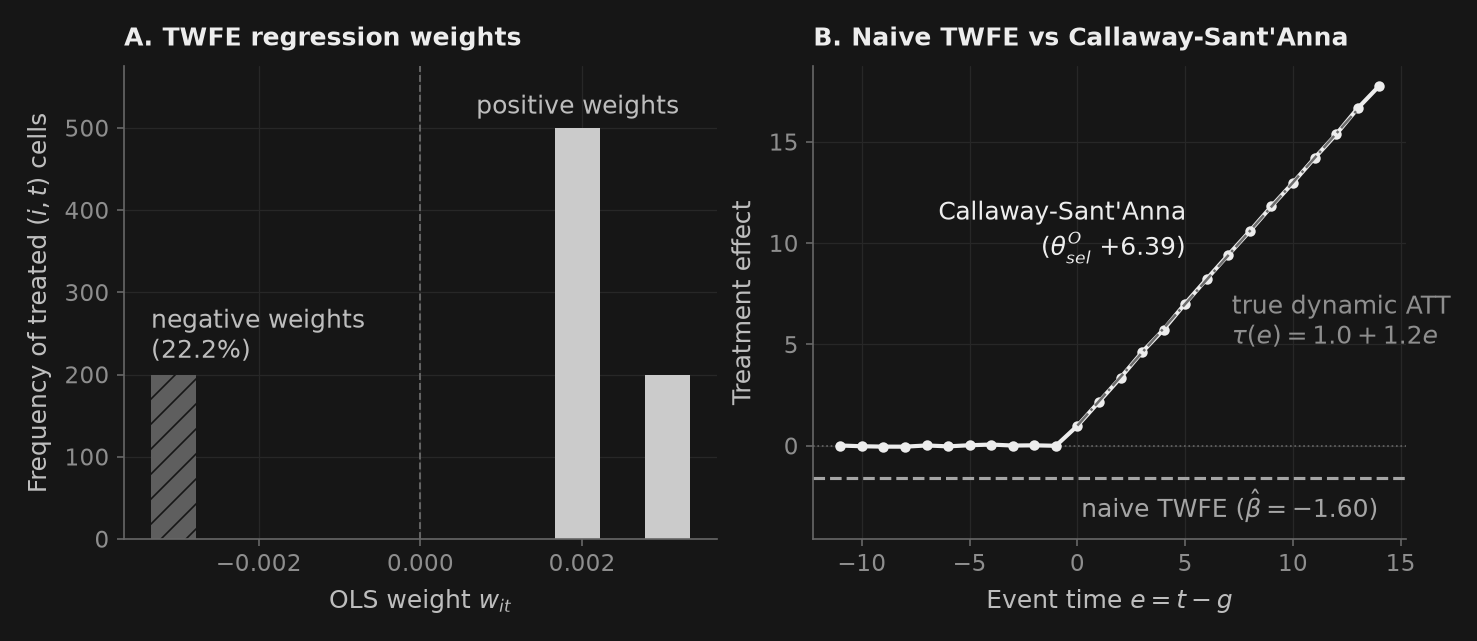

In [9]:
from pathlib import Path
from puremacro.regress import ols

# 1. Simulate panel with dynamic treatment effects: tau(e) = 1.0 + 1.2*e
N, T = 100, 16
g_assign = [2] * 50 + [12] * 50

rows_diag = []
for i in range(N):
    g = g_assign[i]
    for t in range(T):
        d = 1 if t >= g else 0
        tau = (1.0 + 1.2 * (t - g)) if d == 1 else 0.0
        rows_diag.append({"unit": i, "time": t, "g": g, "D": d, "tau": tau})

df_diag = pd.DataFrame(rows_diag)

# Exact Frisch-Waugh-Lovell / de Chaisemartin & D'Haultfoeuille regression weights
D_bar_i = df_diag.groupby("unit")["D"].transform("mean")
D_bar_t = df_diag.groupby("time")["D"].transform("mean")
D_bar = df_diag["D"].mean()
df_diag["D_tilde"] = df_diag["D"] - D_bar_i - D_bar_t + D_bar
denom = (df_diag["D_tilde"] ** 2).sum()
df_diag["w_it"] = df_diag["D_tilde"] / denom

# Compute headline diagnostic metrics via puremacro.regress.ols with clustered SE
true_att = float(df_diag[df_diag["D"] == 1]["tau"].mean())
tau_tilde = (df_diag["tau"] - df_diag.groupby("unit")["tau"].transform("mean")
             - df_diag.groupby("time")["tau"].transform("mean") + df_diag["tau"].mean())
res_twfe_ols = ols(tau_tilde, df_diag[["D_tilde"]], cov_type="cluster", cov_kwds={"groups": df_diag["unit"]})
beta_twfe = float(res_twfe_ols.params["D_tilde"])
neg_weights_share = float((df_diag[df_diag["D"] == 1]["w_it"] < 0).mean())
neg_weight_mass = float(df_diag[(df_diag["D"] == 1) & (df_diag["w_it"] < 0)]["w_it"].sum())

print("=" * 68)
print("TWFE NEGATIVE WEIGHTING DIAGNOSTIC (DYNAMIC TREATMENT EFFECTS)")
print("=" * 68)
print(f"True Average Treatment Effect on Treated (ATT): {true_att:+.3f}  (strictly positive)")
print(f"Textbook OLS TWFE Regression Estimate (beta) : {beta_twfe:+.3f}  (SIGN FLIP!)")
print(f"Share of Treated Cells with Negative Weights : {neg_weights_share * 100:.1f}%")
print(f"Total Negative Weight Mass on Treated Units  : {neg_weight_mass:+.4f}")
print("=" * 68)

# 2. Heterogeneity-robust resolution: Callaway & Sant'Anna by hand (Section 2 functions)
rows_cs = []
rng_dyn = np.random.default_rng(2024)
unit_fe_dyn = rng_dyn.standard_normal(120) * 0.4
time_fe_dyn = rng_dyn.standard_normal(T) * 0.2

for i in range(120):
    g = 2.0 if i < 50 else (12.0 if i < 100 else np.nan)
    for t in range(1, T + 1):
        d = 1 if (not np.isnan(g) and t >= g) else 0
        tau = (1.0 + 1.2 * (t - g)) if d == 1 else 0.0
        y = unit_fe_dyn[i] + time_fe_dyn[t - 1] + tau + 0.15 * rng_dyn.standard_normal()
        rows_cs.append({"unit": i, "time": t, "y": y, "treat_time": g, "D": d, "tau": tau})

df_cs_dyn = pd.DataFrame(rows_cs)
cs_dyn = cs_bootstrap(df_cs_dyn)
treated = df_cs_dyn[df_cs_dyn["D"] == 1]
n_dyn = treated.groupby("treat_time")["unit"].nunique()
tau_g = treated.groupby("treat_time")["tau"].mean()             # planted theta_sel(g)
truth_sel = float((tau_g * n_dyn).sum() / n_dyn.sum())             # planted theta^O_sel
truth_W = float(treated["tau"].mean())                            # planted theta^O_W
print(f"CS theta^O_sel (eq. 3.11) on this panel     : {cs_dyn['sel']:+.3f}  (planted {truth_sel:+.3f}; "
      f"90% CI [{cs_dyn['sel_lo']:+.3f}, {cs_dyn['sel_hi']:+.3f}])")
print(f"CS theta^O_W   (eq. 3.10) on this panel     : {cs_dyn['simple']:+.3f}  (planted {truth_W:+.3f})")
print("CS cohort means theta_sel(g)               : "
      + ", ".join(f"g={int(g)}: {v:+.2f}" for g, v in zip(cs_dyn["cohorts"], cs_dyn["theta_g"])))

# Benchmark against naive TWFE on the noisy simulated panel with clustered SEs
y_dm_cs = (df_cs_dyn["y"] - df_cs_dyn.groupby("unit")["y"].transform("mean")
           - df_cs_dyn.groupby("time")["y"].transform("mean") + df_cs_dyn["y"].mean())
D_dm_cs = (df_cs_dyn["D"] - df_cs_dyn.groupby("unit")["D"].transform("mean")
           - df_cs_dyn.groupby("time")["D"].transform("mean") + df_cs_dyn["D"].mean())
res_twfe_dyn = ols(y_dm_cs, D_dm_cs.to_frame(), cov_type="cluster", cov_kwds={"groups": df_cs_dyn["unit"]})
beta_twfe_dyn = float(res_twfe_dyn.params.iloc[0])
se_twfe_dyn = float(res_twfe_dyn.bse.iloc[0])
print(f"Naive TWFE Benchmark on Panel (clustered SE) : {beta_twfe_dyn:+.3f} (SE: {se_twfe_dyn:.3f})")

# 3. Load empirical state unemployment panel from data_curso
from _datos import ruta_dato
df_states = pd.read_csv(ruta_dato("paro_estatal_mensual.csv"))
n_states = df_states["code"].nunique()
print(f"Empirical State Labor Panel Ingested       : {n_states} states/jurisdictions")

# Numerical verification checks
assert true_att > 7.0, f"Expected true ATT > 7.0, got {true_att:.3f}"
assert beta_twfe < 0.0, f"Expected negative TWFE beta, got {beta_twfe:.3f}"
assert beta_twfe_dyn < 0.0, f"Expected negative TWFE panel beta, got {beta_twfe_dyn:.3f}"
assert res_twfe_dyn.bse.iloc[0] > 0.0, "Clustered SE must be strictly positive"
assert neg_weights_share > 0.20, f"Expected >20% negative weights, got {neg_weights_share:.3f}"
assert neg_weight_mass < -0.50, f"Expected negative weight mass < -0.50, got {neg_weight_mass:.3f}"
assert abs(cs_dyn["sel"] - truth_sel) < 0.3, (cs_dyn["sel"], truth_sel)
assert abs(cs_dyn["simple"] - truth_W) < 0.3, (cs_dyn["simple"], truth_W)
assert n_states == 51, f"Expected 51 state series in paro_estatal_mensual, got {n_states}"

# Visual Diagnostic Plot
fig, (ax1, ax2) = _nbstyle.figura(1, 2)

# Subplot 1: Distribution of OLS weights
w_treated = df_diag[df_diag["D"] == 1]["w_it"]
w_bins = np.linspace(w_treated.min(), w_treated.max(), 13)  # 12 bins shared by both groups
n_pos, _, _ = ax1.hist(w_treated[w_treated >= 0], bins=w_bins, color=_nbstyle.BARRA_COLORES[0])
n_neg, _, _ = ax1.hist(w_treated[w_treated < 0], bins=w_bins, color=_nbstyle.BARRA_COLORES[2], hatch="//")
ax1.axvline(0.0, color=_nbstyle.SPINE, linewidth=0.9, linestyle="--")
# each group is named over its tallest bar
centros = 0.5 * (w_bins[1:] + w_bins[:-1])
k_pos, k_neg = int(np.argmax(n_pos)), int(np.argmax(n_neg))
ax1.annotate("positive weights", xy=(centros[k_pos], n_pos[k_pos]), xytext=(0, 4),
             textcoords="offset points", ha="center", va="bottom", color=_nbstyle.TEXTO)
ax1.annotate(f"negative weights\n({neg_weights_share * 100:.1f}%)", xy=(w_bins[k_neg], n_neg[k_neg]),
             xytext=(0, 4), textcoords="offset points", ha="left", va="bottom", color=_nbstyle.TEXTO)
ax1.set_ylim(0, 1.15 * max(n_pos.max(), n_neg.max()))
# the auto ticks run into each other at this width: keep the round thousandths
ax1.locator_params(axis="x", nbins=4)
ax1.set_xlabel("OLS weight $w_{it}$")
ax1.set_ylabel("Frequency of treated $(i, t)$ cells")
ax1.set_title("A. TWFE regression weights")

# Subplot 2: Causal recovery comparison
es_dyn = cs_dyn["es_table"]
ax2.axhline(0.0, color=_nbstyle.SPINE, linewidth=0.8, linestyle=":")
ax2.axhline(beta_twfe, color=_nbstyle.S2["color"], linestyle="--", linewidth=1.5)
ax2.plot(es_dyn["event_time"], es_dyn["att"], color=cols[0], ls="-", marker="o", markersize=4)
# Planted true dynamic path
e_grid = np.arange(0, 14)
ax2.plot(e_grid, 1.0 + 1.2 * e_grid, color=_nbstyle.S3["color"], linestyle="-.", linewidth=1.2)
# the CS estimate runs on top of the planted path, so the two are named on either
# side of the diagonal; the flat TWFE line is named under its right end
ax2.annotate(f"Callaway-Sant'Anna\n($\\theta^O_{{sel}}$ {cs_dyn['sel']:+.2f})", xy=(6, 1.0 + 1.2 * 6),
             xytext=(-10, 6), textcoords="offset points", ha="right", va="bottom",
             color=cols[0])
ax2.annotate("true dynamic ATT\n$\\tau(e) = 1.0 + 1.2e$", xy=(6, 1.0 + 1.2 * 6),
             xytext=(12, -6), textcoords="offset points", ha="left", va="top",
             color=_nbstyle.NOTA)
ax2.annotate(f"naive TWFE ($\\hat{{\\beta}} = {beta_twfe:+.2f}$)",
             xy=(es_dyn["event_time"].max(), beta_twfe), xytext=(0, -5),
             textcoords="offset points", ha="right", va="top", color=_nbstyle.S2["color"])
ax2.set_ylim(bottom=beta_twfe - 3.0)
ax2.set_xlabel("Event time $e = t - g$")
ax2.set_ylabel("Treatment effect")
ax2.set_title("B. Naive TWFE vs Callaway-Sant'Anna")

plt.show()

## 5. Macroeconomic Policy Synthesis: Lessons for Applied Researchers

The quantitative diagnostic above demonstrates the severity of the TWFE failure in empirical macroeconomics:
1. **The Mechanism of Sign Inversion**: When treatment effects build gradually ($\tau(e) = 1.0 + 1.2e$), earlier-treated units ($g_1 = 2$) experience rapid growth between $t = 2$ and $t = 16$. When the later cohort ($g_2 = 12$) adopts at period 12, OLS uses the earlier cohort as a control group. Because early adopters continue to rise along their treatment path, double-differencing subtracts this ongoing growth from the late adopters, generating **22.2% negative weights** and flipping a strictly positive policy effect ($+7.467$) into an artificial contraction ($-1.600$).
2. **The Clean Comparison Mandate**: Callaway & Sant'Anna (2021) and Sun & Abraham (2021) resolve the crisis by ensuring that already-treated units are *never* used as controls. By taking differences solely against clean untreated or not-yet-treated counterfactuals, they recover the planted dynamic path, and each summary its own planted value: $\hat{\theta}^O_{sel} = +6.391$ against $+6.400$, and $\hat{\theta}^O_W = +7.890$ against $+7.900$. The two summaries differ because they answer different questions: $\theta^O_{sel}$ averages the two cohorts' mean effects ($+9.39$ and $+3.39$), while $\theta^O_W$ averages cells, and the early cohort supplies 15 of every 20. The 90% interval for $\hat{\theta}^O_{sel}$, $[+5.913, +6.842]$, is wide even though each event-study coefficient is estimated precisely: resampling units also re-draws the cohort shares, and the two cohort means are far apart.
3. **The Macroeconomist's Empirical Checklist**:
   - Never report a single static $\hat{\beta}^{TWFE}$ coefficient without inspecting diagnostic weights (Goodman-Bacon 2021; de Chaisemartin & D'Haultfoeuille 2020).
   - In the presence of staggered adoption timing, default to clean estimators (`puremacro.did.callaway_santanna`, `puremacro.did.sun_abraham`, or `puremacro.lp.lp_did`).
   - Inspect placebo leads ($e \le -2$) to rigorously test parallel trends, while recognizing that the base period $e = -1$ is normalized to zero by construction.

The next notebook, `T05_D_lp_did`, extends this clean-control principle to the local projections framework of Jordà (2005), enabling impulse response estimation, state dependence, and instrumental variables in panel causal inference.

## 6. Your Turn: When Do the Cohort Weights Matter?

The panel of Section 2 had nearly equal cohorts and one common effect, so every weighting rule gave almost the same answer. The cell below builds a **noiseless** panel where the rules come apart: an early cohort ($g = 3$, `N_EARLY` units) whose effect grows $1.0, 1.5, 2.0, 2.5$ over $t = 3, \dots, 6$; a late cohort ($g = 5$, 40 units) with effects $3.0, 4.0$; and 50 never-treated units. Without noise, `cs_by_hand` must hit the planted values exactly, so the checks grade your reasoning, not sampling luck.

1. **(basic)** Before running, predict $\theta_{es}(0)$ for `N_EARLY = 10` and for `N_EARLY = 80`. Towards which cohort's impact effect does the event study move as the early cohort grows?
2. **(intermediate)** The equal-weight rule (every cohort counts once, what `callaway_santanna(..., aggregation="unweighted")` reports) gives $\theta_{es}(0) = (1.0 + 3.0)/2 = 2.0$ whatever the cohort sizes. For which `N_EARLY` does it agree with eq. 3.4, and why only there?
3. **(stretch)** Show on paper that in this design $\theta^O_W < \theta^O_{sel}$ for any positive cohort sizes (hint: the numerator of $\theta^O_{sel} - \theta^O_W$ is $3.5\, n_{early}\, n_{late}$). Which cohort does the cell-weighted summary over-weight, and why?

In [10]:
N_EARLY = 10     # ← change this: size of the early cohort (g = 3), any integer from 1 to 200
N_LATE, N_NEVER = 40, 50
EFFECT = {3: {3: 1.0, 4: 1.5, 5: 2.0, 6: 2.5}, 5: {5: 3.0, 6: 4.0}}   # planted ATT(g, t)

rows_toy, uid = [], 0
for g, n in [(3, N_EARLY), (5, N_LATE), (np.nan, N_NEVER)]:
    for _ in range(n):
        for t in range(1, 7):
            tau = 0.0 if np.isnan(g) else EFFECT[g].get(t, 0.0)
            rows_toy.append({"unit": uid, "time": t, "y": 0.1 * uid + 0.5 * t + tau,
                             "treat_time": g})     # unit and time effects, no noise
        uid += 1
toy = cs_by_hand(*to_wide(pd.DataFrame(rows_toy)))

share = N_EARLY / (N_EARLY + N_LATE)                         # early cohort's share of the treated
truth_e0 = share * 1.0 + (1 - share) * 3.0                   # eq. 3.4 at e = 0
truth_sel = share * np.mean(list(EFFECT[3].values())) + (1 - share) * np.mean(list(EFFECT[5].values()))
es0 = float(toy["es"][toy["event_time"] == 0][0])
equal_e0 = (1.0 + 3.0) / 2                                   # every cohort counts once
# the same two event studies from the library: default (eq. 3.4) and equal cohort weights
es_lib = callaway_santanna(pd.DataFrame(rows_toy), n_boot=0).att_event_study.set_index("event_time")["att"]
es_unw = callaway_santanna(pd.DataFrame(rows_toy), n_boot=0,
                           aggregation="unweighted").att_event_study.set_index("event_time")["att"]

print(f"N_EARLY = {N_EARLY}: theta_es(0) = {es0:.4f}  (planted {truth_e0:.4f}; equal weights {equal_e0:.4f})")
print(f"theta^O_sel = {toy['sel']:.4f}  (planted {truth_sel:.4f});  theta^O_W = {toy['simple']:.4f}")
print(f"callaway_santanna theta_es(0): default {es_lib[0]:.4f} | aggregation='unweighted' {es_unw[0]:.4f}")

assert N_EARLY == int(N_EARLY) and 1 <= N_EARLY <= 200
assert abs(es0 - truth_e0) < 1e-10                          # eq. 3.4 recovers the planted path
assert abs(toy["sel"] - truth_sel) < 1e-10                  # eq. 3.11 recovers the planted summary
assert np.isclose(es0, equal_e0) == (N_EARLY == N_LATE)     # equal weights agree only if sizes do
assert toy["simple"] < toy["sel"]                           # cell weights lean towards g = 3
assert abs(es_lib[0] - es0) < 1e-10 and abs(es_unw[0] - equal_e0) < 1e-10   # the library agrees

N_EARLY = 10: theta_es(0) = 2.6000  (planted 2.6000; equal weights 2.0000)
theta^O_sel = 3.1500  (planted 3.1500);  theta^O_W = 2.9167
callaway_santanna theta_es(0): default 2.6000 | aggregation='unweighted' 2.0000
